# 02 — Regression models and comparison

**Task:** using everything known at the close of day *t*, predict the 3M, 5Y and 30Y yields on day *t+1*
(short, medium and long end of the curve).

**Frameworks:** XGBoost · Keras · PyTorch + fastai · PyTorch + TabNet · PyTorch + Lightning Flash
(falls back to plain PyTorch Lightning if Flash cannot be installed, see section 8).

**Key design choice:** models predict the next-day **change** in basis points; the yield level is then
`today's yield + predicted change`. Every model is compared with the **naive forecast** "tomorrow = today"
(predicted change = 0), the standard benchmark for interest-rate forecasting.

In [1]:
import os
os.environ.setdefault("KERAS_BACKEND", "torch")   # Keras 3 running on PyTorch: one deep-learning backend for the whole project

import time
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

FIG = Path("figures")
RES = Path("results")
FIG.mkdir(exist_ok=True)
RES.mkdir(exist_ok=True)

SEED = 42
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
set_seed()

def savefig(name):
    plt.savefig(FIG / f"{name}.png", bbox_inches="tight")

TENORS = ["3M", "1Y", "2Y", "5Y", "10Y", "15Y", "30Y"]
TARGETS = ["3M", "5Y", "30Y"]
HORIZON = 1                      # trading days ahead
TRAIN_END = "2022-12-31"         # train: 2012-2022
VAL_END = "2023-12-31"           # validation: 2023 (early stopping / model selection)
                                 # test: 2024 onwards (never used for training or tuning)

## 1. Load the processed dataset

In [2]:
data = pd.read_csv("data/processed/dataset.csv", index_col=0, parse_dates=True)
print(data.shape, data.index.min().date(), "->", data.index.max().date())
data.head()

(3628, 7) 2012-01-12 -> 2026-11-11


,3M,1Y,2Y,5Y,10Y,15Y,30Y
Date,,,,,,,
2012-01-12,8.50,8.351,7.957,8.273,8.251,8.505,8.548
2012-01-13,8.55,8.324,7.913,8.251,8.192,8.464,8.530
2012-01-16,8.60,8.351,7.935,8.246,8.222,8.482,8.554
2012-01-17,8.55,8.332,7.936,8.259,8.218,8.488,8.516
2012-01-18,8.60,8.392,8.018,8.216,8.190,8.476,8.505


## 2. Features and targets

All features are engineered from the 7 yield series and use only information available at the close of day *t*
(every rolling window looks backwards):

| Group | Features (for each of the 7 tenors unless stated) |
|---|---|
| Yield levels | yield today (%) |
| Short-term change | 1-day change (bps) |
| Momentum | 5-day and 20-day change (bps) |
| Mean reversion | yield minus its own 20-day average (bps) |
| Volatility | standard deviation of daily changes over the last 20 days (bps) |
| Curve shape | 10Y−3M, 30Y−10Y and 5Y−2Y spreads, 2×5Y−2Y−10Y curvature (one set for the whole curve) |

Target: `(yield[t+HORIZON] − yield[t]) × 100`, in basis points.

In [3]:
def build_features(d):
    X = pd.DataFrame(index=d.index)
    for t in TENORS:
        y = d[t]
        d1 = y.diff() * 100
        X[f"y_{t}"] = y
        X[f"d1_{t}"] = d1
        X[f"d5_{t}"] = y.diff(5) * 100
        X[f"d20_{t}"] = y.diff(20) * 100
        X[f"dev20_{t}"] = (y - y.rolling(20).mean()) * 100
        X[f"vol20_{t}"] = d1.rolling(20).std()
    X["slope_10Y_3M"] = d["10Y"] - d["3M"]
    X["slope_30Y_10Y"] = d["30Y"] - d["10Y"]
    X["slope_5Y_2Y"] = d["5Y"] - d["2Y"]
    X["curv_2_5_10"] = 2 * d["5Y"] - d["2Y"] - d["10Y"]
    return X

X_all = build_features(data)
Y_all = pd.DataFrame({t: (data[t].shift(-HORIZON) - data[t]) * 100 for t in TARGETS})

frame = pd.concat([X_all, Y_all.add_prefix("target_")], axis=1).dropna()
FEATURES = list(X_all.columns)
YCOLS = [f"target_{t}" for t in TARGETS]
print(f"{len(FEATURES)} features, {len(frame)} rows")

46 features, 3607 rows


## 3. Chronological split

Time-series data must not be shuffled: a random split would let the model train on days *after* the days it is tested on.

In [4]:
train = frame[frame.index <= TRAIN_END]
val = frame[(frame.index > TRAIN_END) & (frame.index <= VAL_END)]
test = frame[frame.index > VAL_END]
for name, part in [("train", train), ("val", val), ("test", test)]:
    print(f"{name:>5}: {len(part):5d} rows  {part.index.min().date()} -> {part.index.max().date()}")

# Scale features with statistics from the training set only
x_scaler = StandardScaler().fit(train[FEATURES])
Xtr, Xva, Xte = (x_scaler.transform(p[FEATURES]).astype("float32") for p in (train, val, test))

# Neural nets train better with targets on unit scale; we convert predictions back to bps afterwards
Ytr, Yva, Yte = (p[YCOLS].values.astype("float32") for p in (train, val, test))
y_mean, y_std = Ytr.mean(axis=0), Ytr.std(axis=0)
scale_y = lambda y: ((y - y_mean) / y_std).astype("float32")
unscale_y = lambda y: y * y_std + y_mean
Ytr_s, Yva_s = scale_y(Ytr), scale_y(Yva)

# Yield level on day t for each test row, used to turn predicted changes into predicted levels
today_te = data.loc[test.index, TARGETS].values

train:  2661 rows  2012-02-10 -> 2022-12-30
  val:   242 rows  2023-01-02 -> 2023-12-29
 test:   704 rows  2024-01-01 -> 2026-11-09


## 4. Evaluation helpers

Note: since predicted level = today + predicted change, the **RMSE and MAE of levels equal those of changes**.
Only R² differs: R² on levels is ≈ 0.99 for any reasonable model (including the naive one) because yields are so persistent,
so we report R² on both, and judge models mainly by RMSE vs the naive forecast:

- **Skill vs naive** = 1 − RMSE_model / RMSE_naive (positive = better than "tomorrow = today")
- **Direction hit rate** = share of days with a non-zero move where the predicted sign matches the actual sign

In [5]:
results, preds, train_times = [], {}, {}

def evaluate(name, pred_bps, seconds=None):
    preds[name] = pred_bps
    if seconds is not None:
        train_times[name] = seconds
    for j, t in enumerate(TARGETS):
        y, p = Yte[:, j], pred_bps[:, j]
        lvl_true = today_te[:, j] + y / 100
        lvl_pred = today_te[:, j] + p / 100
        moved = y != 0
        results.append({
            "model": name, "tenor": t,
            "RMSE_bps": np.sqrt(mean_squared_error(y, p)),
            "MAE_bps": mean_absolute_error(y, p),
            "R2_change": r2_score(y, p),
            "R2_level": r2_score(lvl_true, lvl_pred),
            "hit_rate": np.mean(np.sign(p[moved]) == np.sign(y[moved])) if name != "Naive" else np.nan,
        })
    out = pd.DataFrame([r for r in results if r["model"] == name]).set_index("tenor")
    return out.drop(columns="model").round(4)

## 5. Baseline: naive forecast (tomorrow = today)

In [6]:
evaluate("Naive", np.zeros_like(Yte))

,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.7783,2.2472,-0.0022,0.9969,NaN
5Y,3.6491,2.3072,-0.0000,0.9891,NaN
30Y,2.6796,1.8447,-0.0002,0.9883,NaN


## 6. XGBoost

Gradient-boosted decision trees. One model with three outputs (one tree ensemble per target).
Early stopping on the validation set picks the number of trees.

In [7]:
from xgboost import XGBRegressor

set_seed()
xgb = XGBRegressor(
    n_estimators=2000, learning_rate=0.02, max_depth=3,
    subsample=0.8, colsample_bytree=0.8, min_child_weight=5, reg_lambda=1.0,
    tree_method="hist", multi_strategy="one_output_per_tree",
    early_stopping_rounds=100, random_state=SEED,
)
t0 = time.time()
xgb.fit(Xtr, Ytr, eval_set=[(Xva, Yva)], verbose=False)
xgb_time = time.time() - t0
print(f"best iteration: {xgb.best_iteration}, trained in {xgb_time:.1f}s")

evaluate("XGBoost", xgb.predict(Xte), xgb_time)

best iteration: 321, trained in 3.6s


,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.7678,2.3490,0.0034,0.9969,0.5136
5Y,3.6881,2.3694,-0.0215,0.9888,0.5053
30Y,2.7322,1.8876,-0.0399,0.9879,0.5287


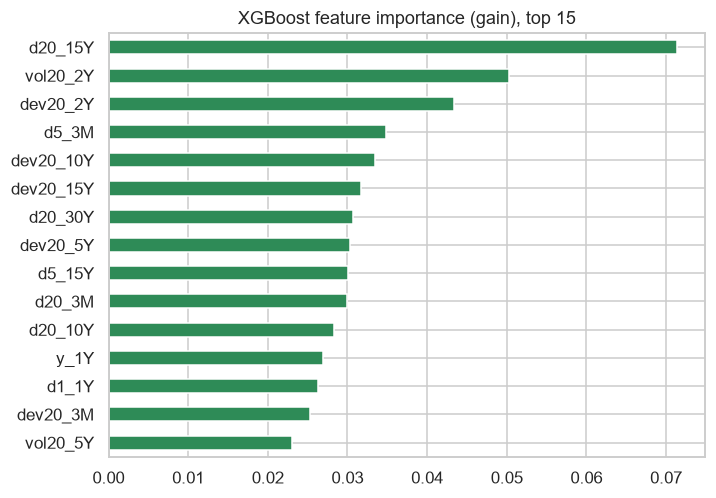

In [8]:
imp = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()
imp.tail(15).plot.barh(figsize=(7, 5), color="seagreen")
plt.title("XGBoost feature importance (gain), top 15")
savefig("09_xgb_importance")
plt.show()

## 7. Keras (multi-layer perceptron)

Feed-forward network: 2 hidden layers (64, 32, ReLU) with dropout, 3 linear outputs, MSE loss, Adam.
Early stopping restores the weights with the lowest validation loss.

stopped after 45 epochs, trained in 12.3s


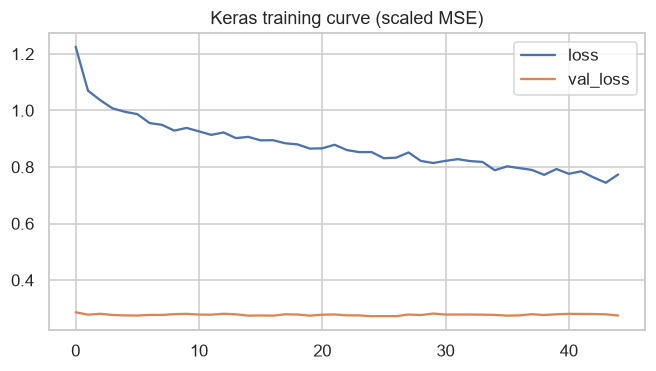

,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.7202,2.4172,0.0284,0.9970,0.5717
5Y,3.6901,2.4197,-0.0226,0.9888,0.4718
30Y,2.7361,1.9368,-0.0428,0.9878,0.4864


In [9]:
import keras
from keras import layers

keras.utils.set_random_seed(SEED)
keras_model = keras.Sequential([
    layers.Input(shape=(len(FEATURES),)),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(32, activation="relu"),
    layers.Dense(len(TARGETS)),
])
keras_model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

t0 = time.time()
history = keras_model.fit(
    Xtr, Ytr_s, validation_data=(Xva, Yva_s),
    epochs=300, batch_size=64, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(patience=20, restore_best_weights=True)],
)
keras_time = time.time() - t0
print(f"stopped after {len(history.history['loss'])} epochs, trained in {keras_time:.1f}s")

pd.DataFrame(history.history).plot(figsize=(7, 3.5), title="Keras training curve (scaled MSE)")
savefig("10_keras_loss")
plt.show()

evaluate("Keras", unscale_y(keras_model.predict(Xte, verbose=0)), keras_time)

## 8. PyTorch + fastai

fastai's `tabular_learner` builds an MLP with batch-norm and dropout and trains it with the one-cycle learning-rate policy.
`num_workers=0` keeps data loading in the main process (needed on Windows inside Jupyter).

In [10]:
from fastai.tabular.all import (TabularPandas, RegressionBlock, tabular_learner,
                                MSELossFlat, EarlyStoppingCallback, rmse)

set_seed()
trval = pd.DataFrame(np.vstack([Xtr, Xva]), columns=FEATURES)
trval[YCOLS] = np.vstack([Ytr_s, Yva_s])
splits = (list(range(len(Xtr))), list(range(len(Xtr), len(Xtr) + len(Xva))))

to = TabularPandas(trval, procs=[], cat_names=[], cont_names=FEATURES, y_names=YCOLS,
                   y_block=RegressionBlock(n_out=len(TARGETS)), splits=splits)
dls = to.dataloaders(bs=64, num_workers=0)
fastai_learner = tabular_learner(dls, layers=[64, 32], n_out=len(TARGETS),
                                 loss_func=MSELossFlat(), metrics=rmse)

t0 = time.time()
with fastai_learner.no_bar():
    fastai_learner.fit_one_cycle(40, 1e-3, cbs=[EarlyStoppingCallback(monitor="valid_loss", patience=8)])
fastai_time = time.time() - t0
print(f"trained in {fastai_time:.1f}s")

test_dl = fastai_learner.dls.test_dl(pd.DataFrame(Xte, columns=FEATURES))
with fastai_learner.no_bar():
    fastai_pred, _ = fastai_learner.get_preds(dl=test_dl)
evaluate("fastai", unscale_y(fastai_pred.numpy()), fastai_time)

[0, 1.3016856908798218, 0.3726772665977478, 0.6104729771614075, '00:00']
[1, 1.182066559791565, 0.3683170974254608, 0.6068913340568542, '00:00']
[2, 1.0707240104675293, 0.3344103991985321, 0.5782822966575623, '00:00']
[3, 0.9652429819107056, 0.31898775696754456, 0.5647900104522705, '00:00']
[4, 0.9818450808525085, 0.30317914485931396, 0.5506170392036438, '00:00']
[5, 0.9715527296066284, 0.2896309196949005, 0.5381736755371094, '00:00']
[6, 0.9248620867729187, 0.3012036383152008, 0.5488201975822449, '00:00']
[7, 0.8787276148796082, 0.2915404736995697, 0.5399448871612549, '00:00']
[8, 0.9364040493965149, 0.28752976655960083, 0.5362180471420288, '00:00']
[9, 0.8273529410362244, 0.28456518054008484, 0.5334464907646179, '00:00']
[10, 0.8433575630187988, 0.29128551483154297, 0.5397087335586548, '00:00']
[11, 0.9480499029159546, 0.27898773550987244, 0.5281928777694702, '00:00']
[12, 0.8695077300071716, 0.29184484481811523, 0.5402266383171082, '00:00']
[13, 0.8177706599235535, 0.281131744384765

,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.8604,2.5690,-0.0462,0.9967,0.5291
5Y,3.8891,2.5473,-0.1359,0.9876,0.5084
30Y,2.7797,1.9627,-0.0763,0.9875,0.4819


## 9. PyTorch + TabNet

TabNet (Arik & Pfister, Google, 2019) uses sequential **attention**: at each decision step a learned mask selects which
features to use. The masks give a built-in feature-importance measure, which makes TabNet more transparent than a plain MLP.

In [11]:
from pytorch_tabnet.tab_model import TabNetRegressor

set_seed()
tabnet = TabNetRegressor(n_d=16, n_a=16, n_steps=3, gamma=1.5, seed=SEED, verbose=0,
                         optimizer_params=dict(lr=2e-2))
t0 = time.time()
tabnet.fit(Xtr, Ytr_s, eval_set=[(Xva, Yva_s)], eval_name=["val"], eval_metric=["rmse"],
           max_epochs=200, patience=20, batch_size=256, virtual_batch_size=64)
tabnet_time = time.time() - t0
print(f"best epoch: {tabnet.best_epoch}, trained in {tabnet_time:.1f}s")

evaluate("TabNet", unscale_y(tabnet.predict(Xte)), tabnet_time)


Early stopping occurred at epoch 35 with best_epoch = 15 and best_val_rmse = 0.51408
best epoch: 15, trained in 14.5s


,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.7664,2.3057,0.0041,0.9969,0.5174
5Y,3.6486,2.3188,0.0002,0.9891,0.5191
30Y,2.6998,1.8781,-0.0153,0.9882,0.4909


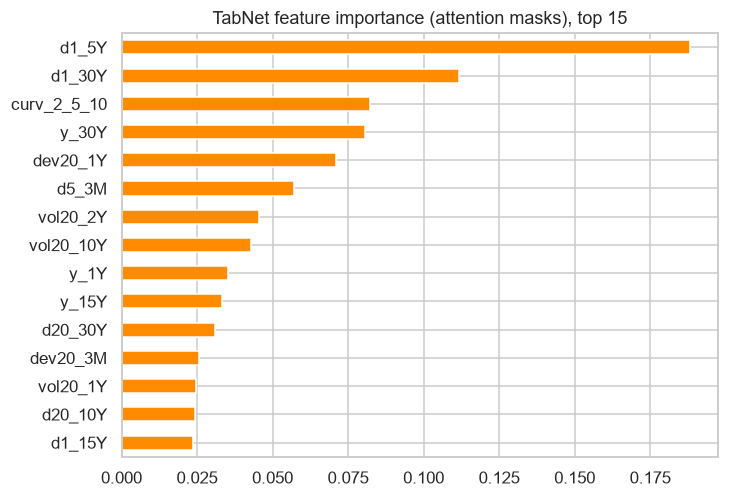

In [12]:
tn_imp = pd.Series(tabnet.feature_importances_, index=FEATURES).sort_values()
tn_imp.tail(15).plot.barh(figsize=(7, 5), color="darkorange")
plt.title("TabNet feature importance (attention masks), top 15")
savefig("11_tabnet_importance")
plt.show()

## 10. PyTorch + Lightning Flash

**Lightning Flash** was a high-level task library on top of PyTorch Lightning. Lightning AI archived it in 2023; its last
release (0.8.2) depends on old versions of PyTorch / Lightning and usually fails to install alongside current libraries.

The cell below uses Flash if it is importable. Otherwise it falls back to the same idea written directly in
**PyTorch Lightning** (the library Flash was built on): an MLP inside a `LightningModule`, trained by the Lightning `Trainer`
with early stopping and best-checkpoint restore.

In [13]:
try:
    import flash
    from flash.tabular import TabularRegressionData, TabularRegressor
    FLASH_AVAILABLE = True
    print("Lightning Flash", flash.__version__)
except Exception as e:
    FLASH_AVAILABLE = False
    print("Lightning Flash not available ->", type(e).__name__, str(e)[:200])
    print("Using the PyTorch Lightning fallback.")

Lightning Flash not available -> ModuleNotFoundError No module named 'flash'
Using the PyTorch Lightning fallback.


In [14]:
import lightning as L
from lightning.pytorch.callbacks import EarlyStopping, ModelCheckpoint
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

class YieldMLP(L.LightningModule):
    def __init__(self, n_in, n_out, lr=1e-3):
        super().__init__()
        self.save_hyperparameters()
        self.net = nn.Sequential(
            nn.Linear(n_in, 64), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(64, 32), nn.ReLU(),
            nn.Linear(32, n_out),
        )
        self.loss_fn = nn.MSELoss()

    def forward(self, x):
        return self.net(x)

    def training_step(self, batch, _):
        x, y = batch
        loss = self.loss_fn(self(x), y)
        self.log("train_loss", loss)
        return loss

    def validation_step(self, batch, _):
        x, y = batch
        self.log("val_loss", self.loss_fn(self(x), y))

    def configure_optimizers(self):
        return torch.optim.Adam(self.parameters(), lr=self.hparams.lr)

def loader(X, Y=None, shuffle=False):
    tensors = [torch.tensor(X)] + ([torch.tensor(Y)] if Y is not None else [])
    return DataLoader(TensorDataset(*tensors), batch_size=64, shuffle=shuffle, num_workers=0)

LIGHTNING_NAME = "Lightning Flash" if FLASH_AVAILABLE else "PyTorch Lightning"

In [15]:
set_seed()
t0 = time.time()
if FLASH_AVAILABLE:
    tr_df = pd.DataFrame(Xtr, columns=FEATURES); tr_df[YCOLS] = Ytr_s
    va_df = pd.DataFrame(Xva, columns=FEATURES); va_df[YCOLS] = Yva_s
    te_df = pd.DataFrame(Xte, columns=FEATURES)
    datamodule = TabularRegressionData.from_data_frame(
        numerical_fields=FEATURES, target_fields=YCOLS,
        train_data_frame=tr_df, val_data_frame=va_df, predict_data_frame=te_df, batch_size=64)
    flash_model = TabularRegressor.from_data(datamodule, learning_rate=1e-3)
    trainer = flash.Trainer(max_epochs=100, callbacks=[EarlyStopping("val_loss", patience=20)],
                            enable_progress_bar=False, logger=False)
    trainer.fit(flash_model, datamodule=datamodule)
    lightning_pred = np.vstack([np.asarray(b) for b in trainer.predict(flash_model, datamodule=datamodule)])
else:
    ckpt = ModelCheckpoint(dirpath="checkpoints", monitor="val_loss", mode="min", save_top_k=1)
    trainer = L.Trainer(max_epochs=300, accelerator="cpu", deterministic=True,
                        callbacks=[EarlyStopping("val_loss", patience=20), ckpt],
                        enable_progress_bar=False, enable_model_summary=False, logger=False)
    lit_model = YieldMLP(len(FEATURES), len(TARGETS))
    trainer.fit(lit_model, loader(Xtr, Ytr_s, shuffle=True), loader(Xva, Yva_s))
    lit_model = YieldMLP.load_from_checkpoint(ckpt.best_model_path)
    lit_model.eval()
    with torch.no_grad():
        lightning_pred = lit_model(torch.tensor(Xte)).numpy()
    print(f"stopped at epoch {trainer.current_epoch}, best val_loss {ckpt.best_model_score:.4f}")
lightning_time = time.time() - t0
print(f"trained in {lightning_time:.1f}s")

evaluate(LIGHTNING_NAME, unscale_y(lightning_pred), lightning_time)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


stopped at epoch 23, best val_loss 0.2681
trained in 5.0s


,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate
tenor,,,,,
3M,3.7286,2.2931,0.0240,0.9969,0.5329
5Y,3.6597,2.3319,-0.0058,0.9890,0.5115
30Y,2.6893,1.8731,-0.0075,0.9883,0.5468


# Results

## 11. Metrics on the test set (2024 onwards)

In [16]:
MODELS = ["Naive", "XGBoost", "Keras", "fastai", "TabNet", LIGHTNING_NAME]
res = pd.DataFrame(results)
res["skill_vs_naive"] = 1 - res["RMSE_bps"] / res["tenor"].map(
    res[res.model == "Naive"].set_index("tenor")["RMSE_bps"])
res = res.set_index(["model", "tenor"]).loc[MODELS]
res.to_csv(RES / "metrics_by_tenor.csv")
res.round(4)

RMSE_bps  MAE_bps  R2_change  R2_level  hit_rate  \
model             tenor                                                     
Naive             3M       3.7783   2.2472    -0.0022    0.9969       NaN   
                  5Y       3.6491   2.3072    -0.0000    0.9891       NaN   
                  30Y      2.6796   1.8447    -0.0002    0.9883       NaN   
XGBoost           3M       3.7678   2.3490     0.0034    0.9969    0.5136   
                  5Y       3.6881   2.3694    -0.0215    0.9888    0.5053   
                  30Y      2.7322   1.8876    -0.0399    0.9879    0.5287   
Keras             3M       3.7202   2.4172     0.0284    0.9970    0.5717   
                  5Y       3.6901   2.4197    -0.0226    0.9888    0.4718   
                  30Y      2.7361   1.9368    -0.0428    0.9878    0.4864   
fastai            3M       3.8604   2.5690    -0.0462    0.9967    0.5291   
                  5Y       3.8891   2.5473    -0.1359    0.9876    0.5084   
                  30Y      2.7797   1.9627    -0.0763    0.9875    0.4819   
TabNet            3M       3.7664   2.3057     0.0041    0.9969    0.5174   
                  5Y       3.6486   2.3188     0.0002    0.9891    0.5191   
                  30Y      2.6998   1.8781    -0.0153    0.9882    0.4909   
PyTorch Lightning 3M       3.7286   2.2931     0.0240    0.9969    0.5329   
                  5Y       3.6597   2.3319    -0.0058    0.9890    0.5115   
                  30Y      2.6893   1.8731    -0.0075    0.9883    0.5468   

                         skill_vs_naive  
model             tenor                  
Naive             3M             0.0000  
                  5Y             0.0000  
                  30Y            0.0000  
XGBoost           3M             0.0028  
                  5Y            -0.0107  
                  30Y           -0.0197  
Keras             3M             0.0154  
                  5Y            -0.0112  
                  30Y           -0.0211  
fastai            3M            -0.0217  
                  5Y            -0.0658  
                  30Y           -0.0374  
TabNet            3M             0.0031  
                  5Y             0.0001  
                  30Y           -0.0075  
PyTorch Lightning 3M             0.0132  
                  5Y            -0.0029  
                  30Y           -0.0036

In [17]:
summary = res.groupby(level="model", sort=False)[["RMSE_bps", "MAE_bps", "R2_change", "R2_level", "hit_rate", "skill_vs_naive"]].mean()
summary["train_time_s"] = pd.Series(train_times)
summary.to_csv(RES / "metrics_summary.csv")
summary.round(4)

,RMSE_bps,MAE_bps,R2_change,R2_level,hit_rate,skill_vs_naive,train_time_s
model,,,,,,,
Naive,3.3690,2.1330,-0.0008,0.9914,NaN,0.0000,NaN
XGBoost,3.3961,2.2020,-0.0193,0.9912,0.5159,-0.0092,3.5617
Keras,3.3821,2.2579,-0.0123,0.9912,0.5100,-0.0057,12.3350
fastai,3.5097,2.3596,-0.0861,0.9906,0.5064,-0.0416,6.9418
TabNet,3.3716,2.1675,-0.0037,0.9914,0.5092,-0.0014,14.5416
PyTorch Lightning,3.3592,2.1660,0.0036,0.9914,0.5304,0.0022,4.9679


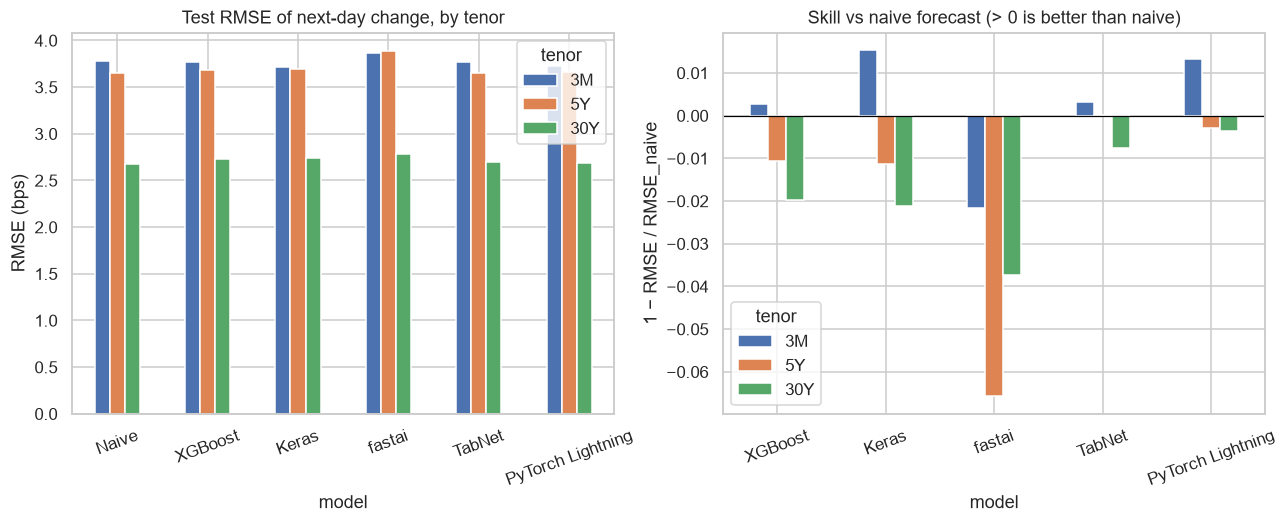

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
res["RMSE_bps"].unstack().loc[MODELS, TARGETS].plot.bar(ax=axes[0], rot=20)
axes[0].set_ylabel("RMSE (bps)")
axes[0].set_title("Test RMSE of next-day change, by tenor")
res["skill_vs_naive"].unstack().loc[MODELS[1:], TARGETS].plot.bar(ax=axes[1], rot=20)
axes[1].axhline(0, color="black", lw=0.8)
axes[1].set_ylabel("1 − RMSE / RMSE_naive")
axes[1].set_title("Skill vs naive forecast (> 0 is better than naive)")
savefig("12_model_comparison")
plt.show()

## 12. Predictions vs actual

Lowest average RMSE: PyTorch Lightning


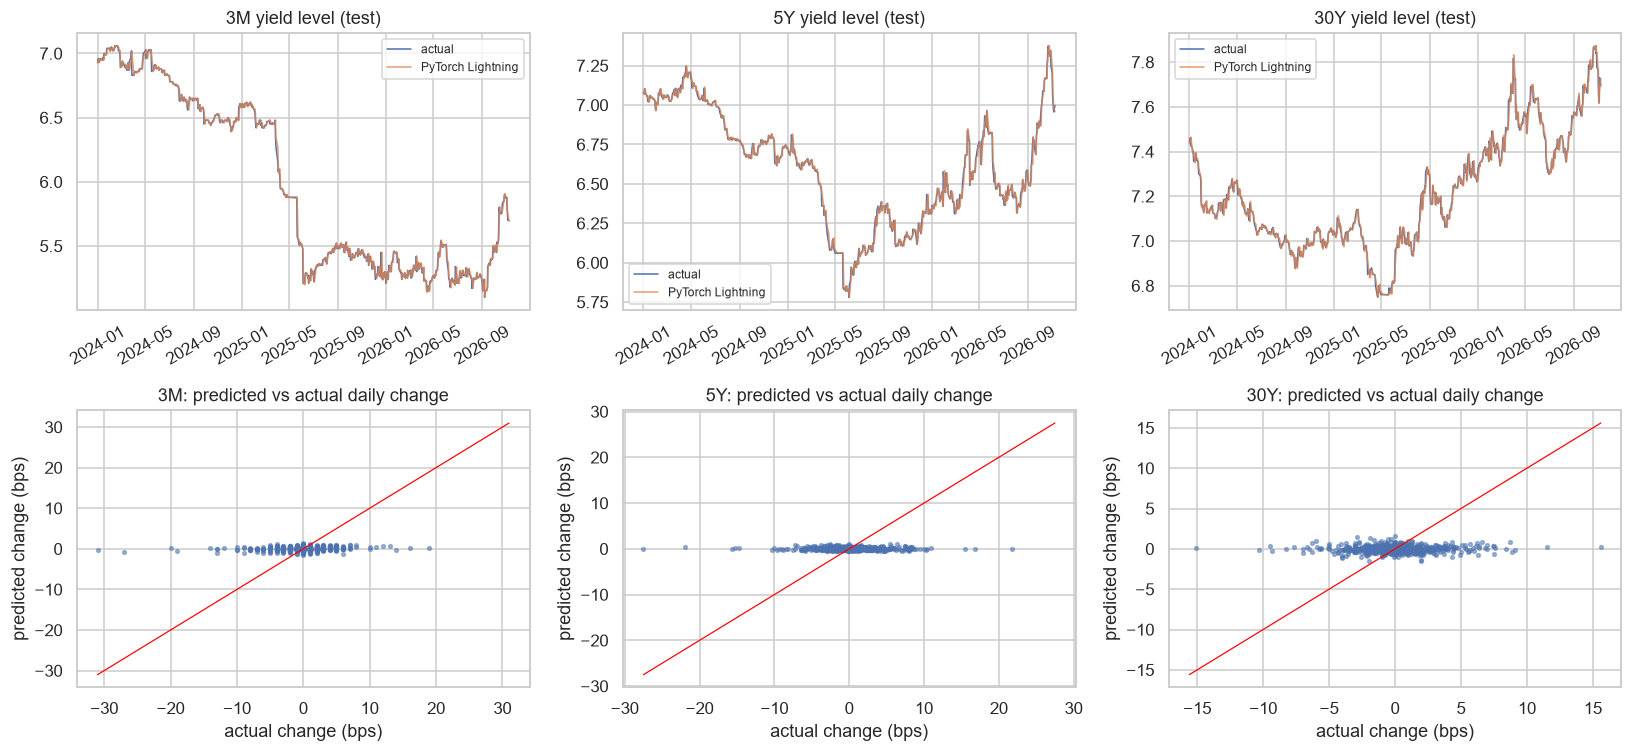

In [19]:
best = summary.drop("Naive")["RMSE_bps"].idxmin()
print("Lowest average RMSE:", best)
p = preds[best]

fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for j, t in enumerate(TARGETS):
    lvl_true = pd.Series(today_te[:, j] + Yte[:, j] / 100, index=test.index)
    lvl_pred = pd.Series(today_te[:, j] + p[:, j] / 100, index=test.index)
    axes[0, j].plot(lvl_true.index, lvl_true, lw=1, label="actual")
    axes[0, j].plot(lvl_pred.index, lvl_pred, lw=1, alpha=0.8, label=f"{best}")
    axes[0, j].set_title(f"{t} yield level (test)")
    axes[0, j].tick_params(axis="x", rotation=30)
    axes[0, j].legend(fontsize=8)
    axes[1, j].scatter(Yte[:, j], p[:, j], s=6, alpha=0.5)
    lim = np.abs(Yte[:, j]).max()
    axes[1, j].plot([-lim, lim], [-lim, lim], color="red", lw=0.8)
    axes[1, j].set_xlabel("actual change (bps)")
    axes[1, j].set_ylabel("predicted change (bps)")
    axes[1, j].set_title(f"{t}: predicted vs actual daily change")
plt.tight_layout()
savefig("13_best_model_predictions")
plt.show()

## 13. Transparency: which features drive each model?

XGBoost and TabNet have built-in importances, but the MLPs (Keras, fastai, Lightning) do not.
To compare all models on the same footing we use **permutation importance** on the test set: shuffle one group of
features, and measure how much the RMSE gets worse. Bigger increase = the model relies more on that group.

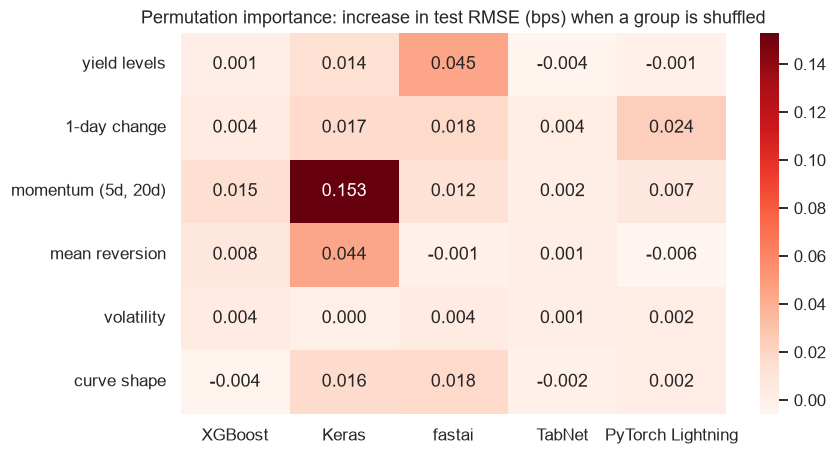

In [20]:
GROUPS = {
    "yield levels": [f"y_{t}" for t in TENORS],
    "1-day change": [f"d1_{t}" for t in TENORS],
    "momentum (5d, 20d)": [f"d5_{t}" for t in TENORS] + [f"d20_{t}" for t in TENORS],
    "mean reversion": [f"dev20_{t}" for t in TENORS],
    "volatility": [f"vol20_{t}" for t in TENORS],
    "curve shape": ["slope_10Y_3M", "slope_30Y_10Y", "slope_5Y_2Y", "curv_2_5_10"],
}
assert sorted(sum(GROUPS.values(), [])) == sorted(FEATURES)

def fastai_predict(X):
    with fastai_learner.no_bar():
        out, _ = fastai_learner.get_preds(dl=fastai_learner.dls.test_dl(pd.DataFrame(X, columns=FEATURES)))
    return unscale_y(out.numpy())

predictors = {
    "XGBoost": lambda X: xgb.predict(X),
    "Keras": lambda X: unscale_y(keras_model.predict(X, verbose=0)),
    "fastai": fastai_predict,
    "TabNet": lambda X: unscale_y(tabnet.predict(X)),
}
if not FLASH_AVAILABLE:
    predictors[LIGHTNING_NAME] = lambda X: unscale_y(lit_model(torch.tensor(X)).detach().numpy())

def rmse_all(pred):
    return np.sqrt(((pred - Yte) ** 2).mean())

rng = np.random.default_rng(SEED)
perm = {}
for name, predict in predictors.items():
    base = rmse_all(predict(Xte))
    scores = {}
    for g, cols in GROUPS.items():
        idx = [FEATURES.index(c) for c in cols]
        deltas = []
        for _ in range(3):
            Xp = Xte.copy()
            Xp[:, idx] = Xp[rng.permutation(len(Xp))][:, idx]
            deltas.append(rmse_all(predict(Xp)) - base)
        scores[g] = np.mean(deltas)
    perm[name] = scores

perm = pd.DataFrame(perm)
perm.to_csv(RES / "permutation_importance.csv")
plt.figure(figsize=(8, 4.5))
sns.heatmap(perm, annot=True, fmt=".3f", cmap="Reds")
plt.title("Permutation importance: increase in test RMSE (bps) when a group is shuffled")
savefig("14_permutation_importance")
plt.show()

## 14. Simplicity and efficiency facts

Objective facts to support the qualitative comparison (simplicity / transparency / efficacy) in the report.

In [21]:
def n_params_torch(m):
    return sum(p.numel() for p in m.parameters())

facts = pd.DataFrame({
    "train_time_s": pd.Series(train_times),
    "trainable_params": pd.Series({
        "XGBoost": np.nan,
        "Keras": keras_model.count_params(),
        "fastai": n_params_torch(fastai_learner.model),
        "TabNet": n_params_torch(tabnet.network),
        LIGHTNING_NAME: n_params_torch(lit_model) if not FLASH_AVAILABLE else n_params_torch(flash_model),
    }),
    "trees": pd.Series({"XGBoost": (xgb.best_iteration + 1) * len(TARGETS)}),
    "built_in_importance": pd.Series({"XGBoost": "yes (gain)", "Keras": "no", "fastai": "no",
                                      "TabNet": "yes (attention masks)", LIGHTNING_NAME: "no"}),
}).loc[MODELS[1:]]
facts.to_csv(RES / "model_facts.csv")
facts

,train_time_s,trainable_params,trees,built_in_importance
XGBoost,3.561671,NaN,966.0,yes (gain)
Keras,12.335015,5187.0,NaN,no
fastai,6.941782,5375.0,NaN,no
TabNet,14.541555,26140.0,NaN,yes (attention masks)
PyTorch Lightning,4.967851,5187.0,NaN,no
